In [ ]:
# ==========================================
# 1. INSTALL & IMPORT LIBRARIES
# ==========================================
!pip install openpyxl scikit-optimize shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
import shap
import os, gc
from google.colab import drive
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, auc, cohen_kappa_score,
    precision_score, recall_score, f1_scorea
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 3.7 MB/s eta 0:00:00


In [ ]:
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Dataset shape: (1998, 9)


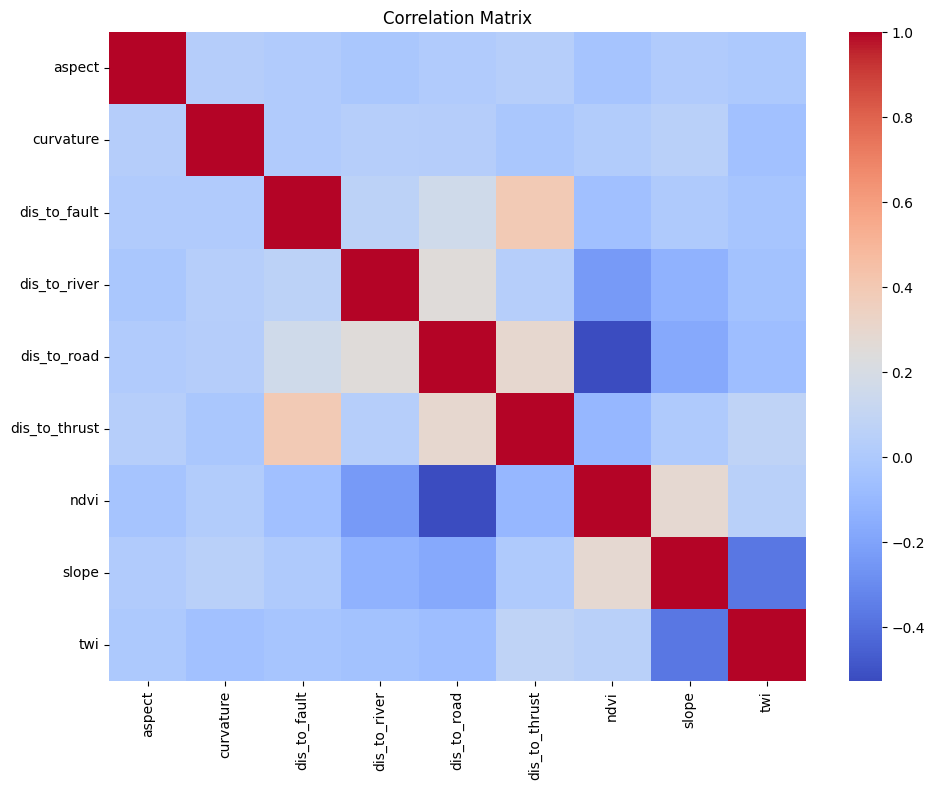

In [ ]:
# ==========================================
# 2. PATHS
# ==========================================
# excel_path = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/ls_non_ls_final.xlsx"
excel_path = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/Filtered_Excel files/ls_non_ls_final_3x3.xlsx"
output_path = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/outputs/"
os.makedirs(output_path, exist_ok=True)


# ==========================================
# 3. LOAD DATA
# ==========================================
df = pd.read_excel(excel_path)
df.columns = df.columns.str.strip()
df = df.drop(["ndwi", "roughness","X","Y"], axis=1, errors='ignore')
df = df.dropna()

y = df['ID'].values
X = df.drop(columns=['ID'])
feature_names = X.columns.tolist()

print("Dataset shape:", X.shape)


# ==========================================
# 4. CORRELATION MATRIX
# ==========================================
plt.figure(figsize=(10,8))
sns.heatmap(X.corr(), cmap='coolwarm')
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(f"{output_path}/correlation_matrix.png")
plt.show()


🔎 Tuning RF...
Best Params: OrderedDict({'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2, 'n_estimators': 150})
AUC: 0.75105625


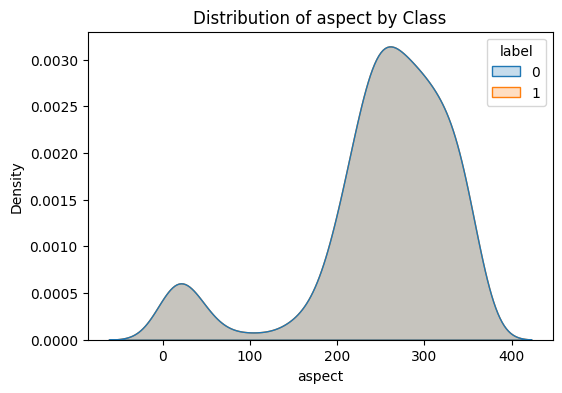

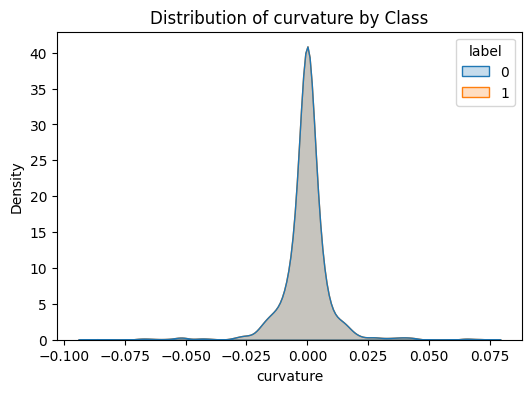

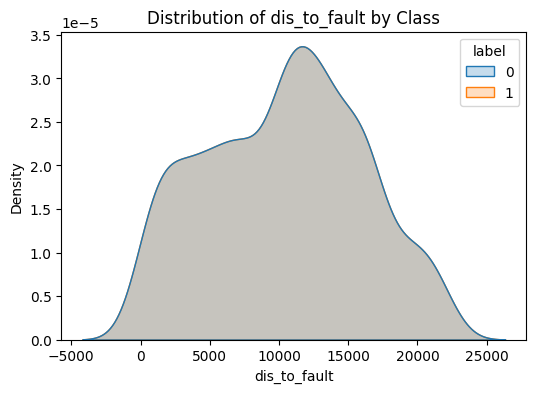

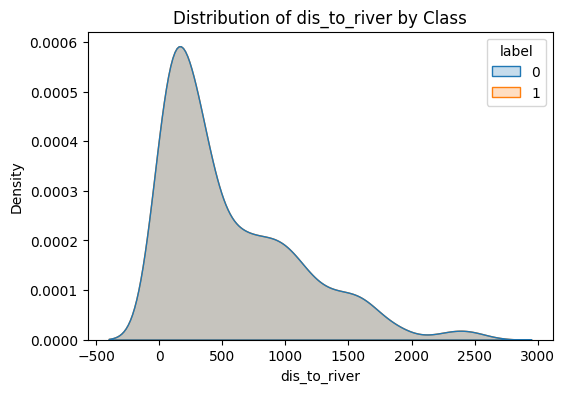

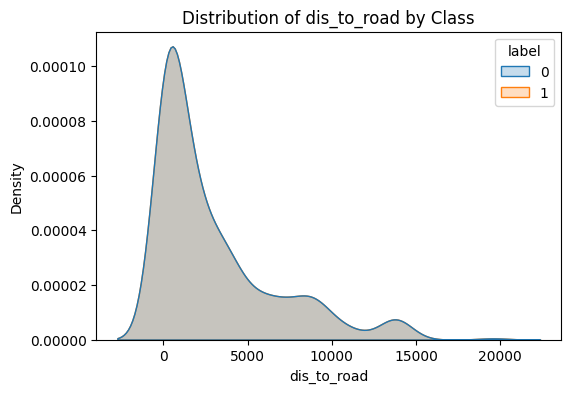

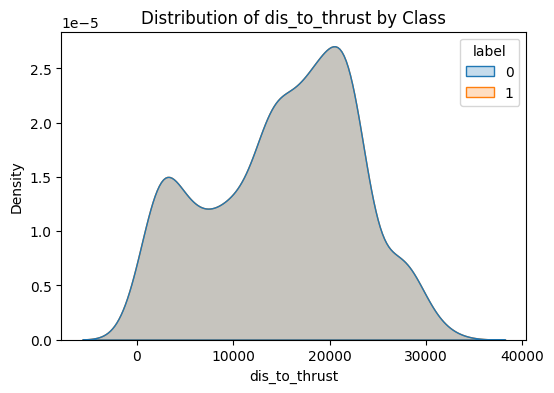

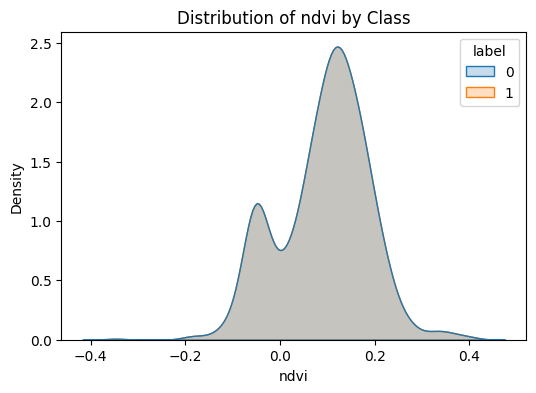

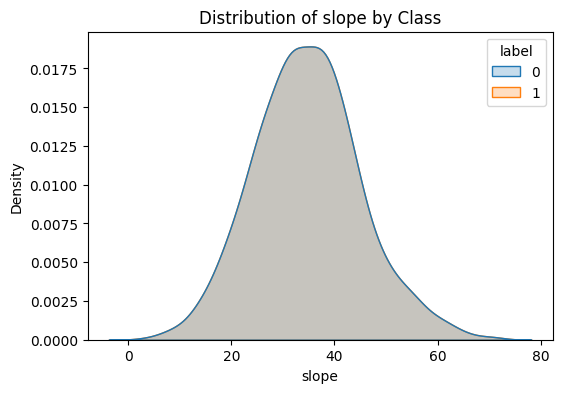

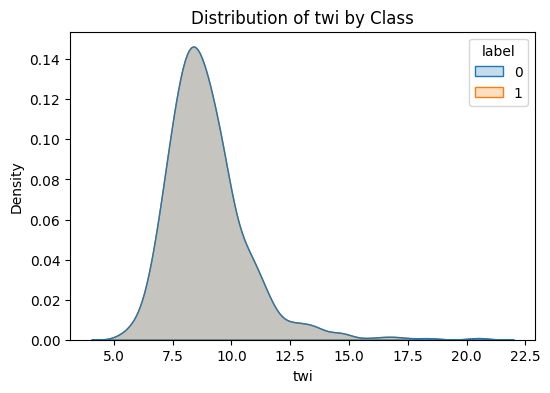


🔎 Tuning SVM...
Best Params: OrderedDict({'model__C': 20.0, 'model__gamma': 0.006679510618014053, 'model__kernel': 'rbf'})
AUC: 0.57609375


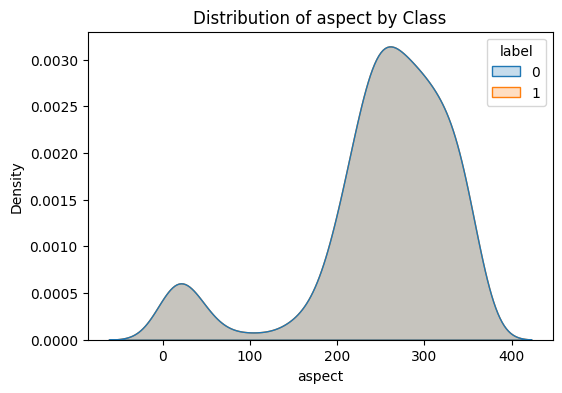

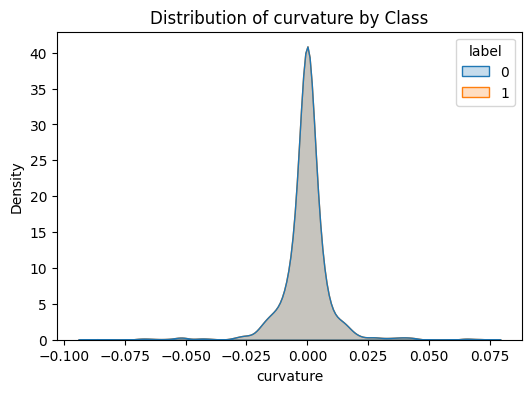

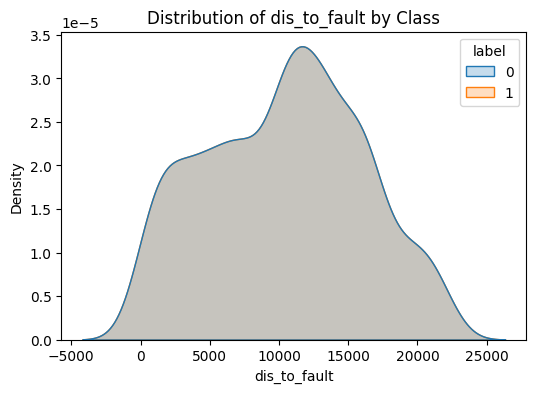

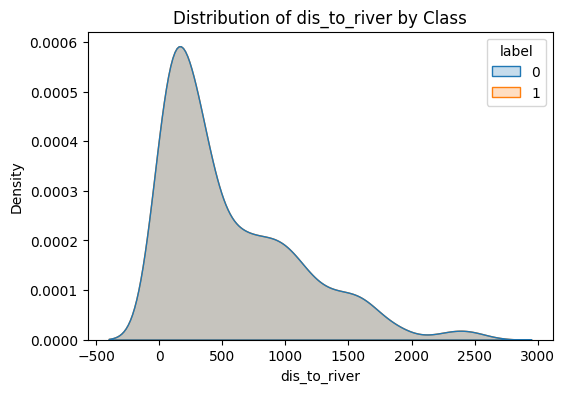

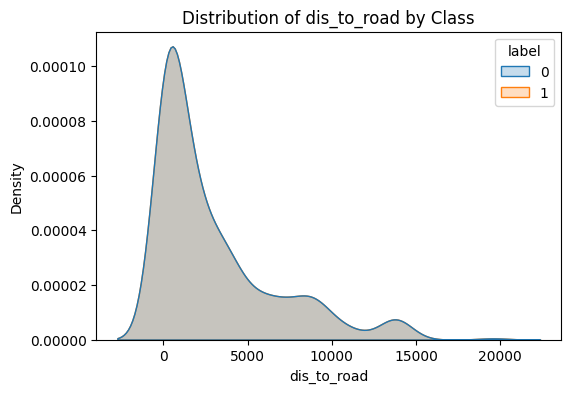

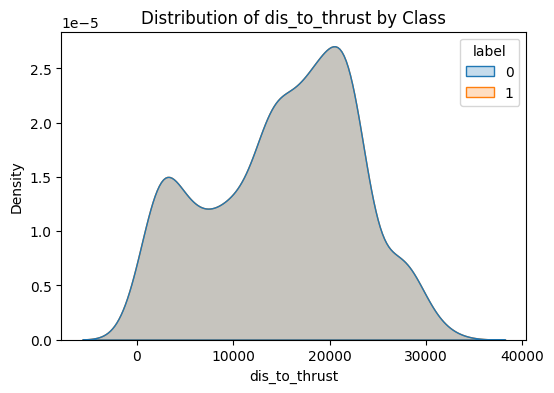

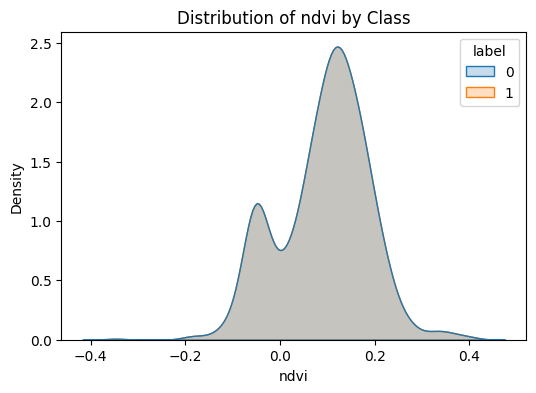

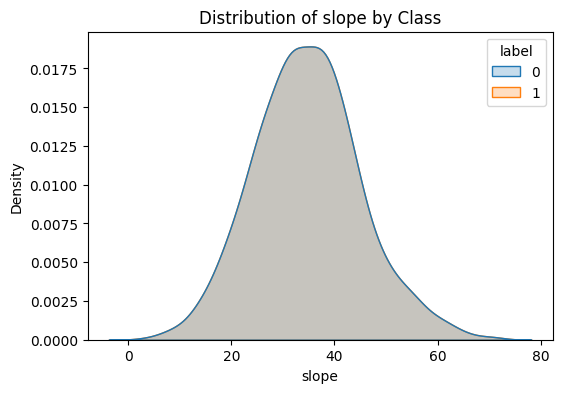

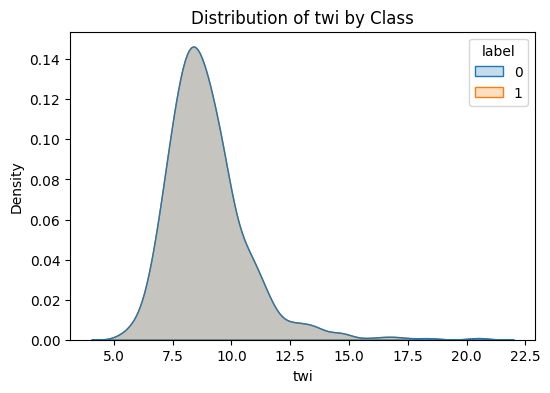


🔎 Tuning XGB...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [18:19:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [18:19:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [18:19:43] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [18:19:43] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: OrderedDict({'colsample_bytree': 0.6, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 150, 'subsample': 1.0})
AUC: 0.7124937499999999


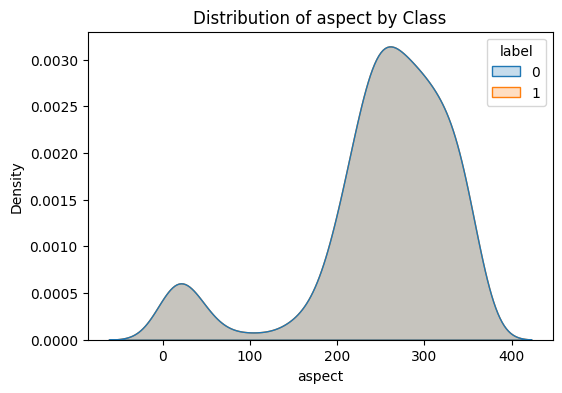

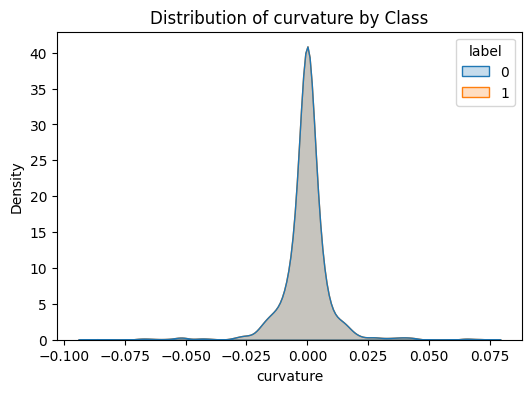

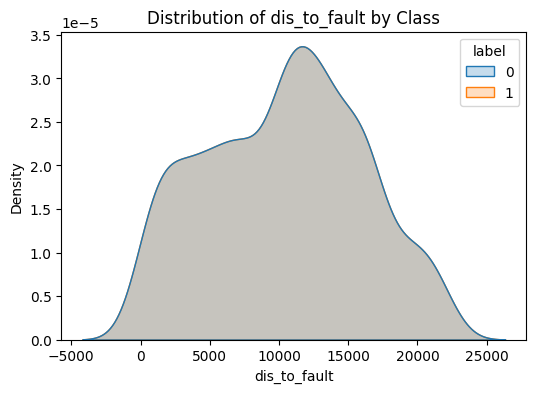

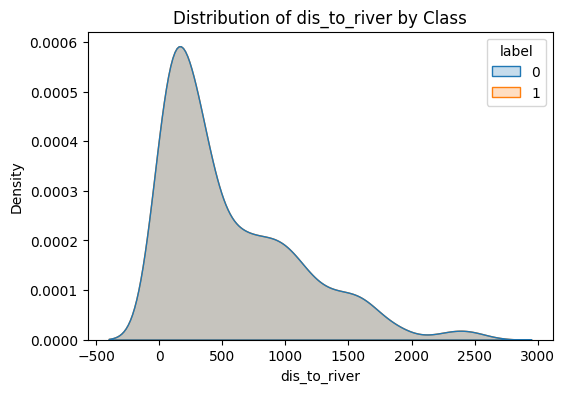

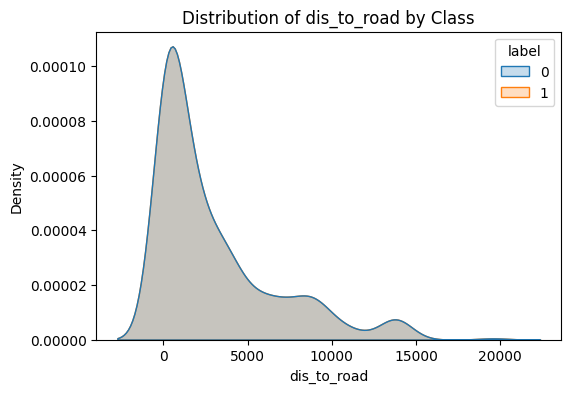

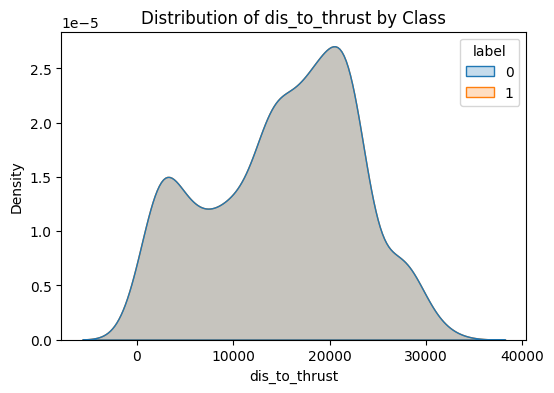

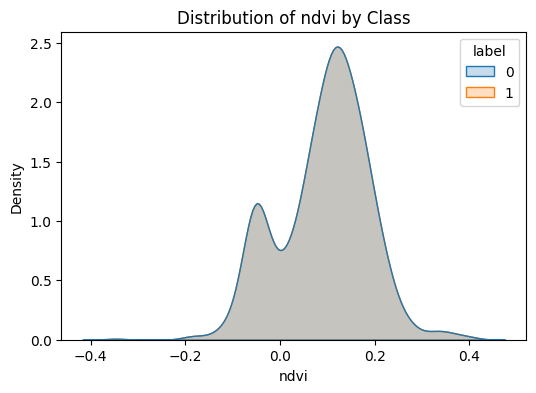

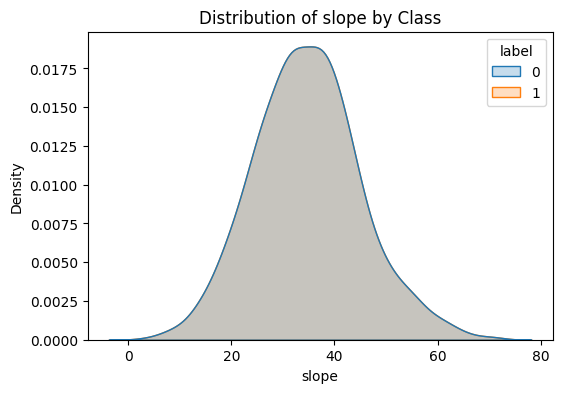

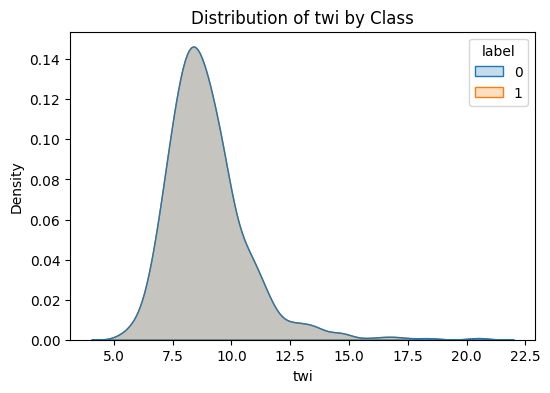

     Accuracy   Kappa        F1  Precision  Recall       AUC
RF    0.68000  0.3600  0.679198   0.680905  0.6775  0.751056
SVM   0.54875  0.0975  0.532988   0.552279  0.5150  0.576094
XGB   0.64875  0.2975  0.660218   0.639344  0.6825  0.712494


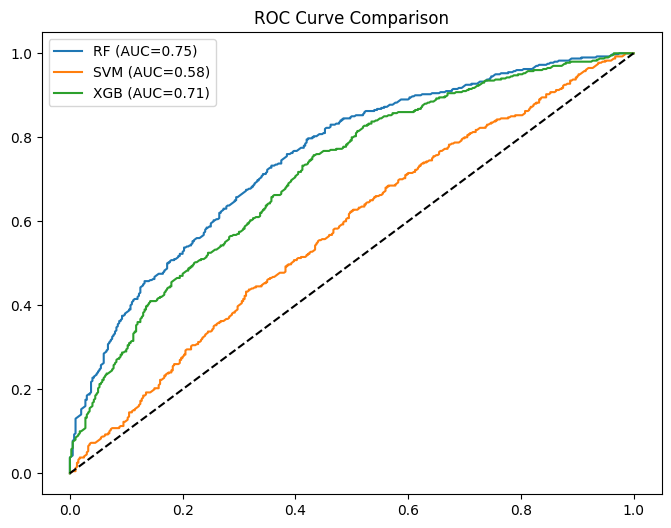

In [ ]:
# ==========================================
# 5. STRATIFIED TRAIN TEST SPLIT
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.4,
    stratify=y,
    random_state=42
)


# ==========================================
# 6. DEFINE MODELS & SEARCH SPACES
# ==========================================
models = {
    "RF": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, class_weight='balanced', random_state=42),
    "XGB": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

param_spaces = {
    "RF": {
        'n_estimators': Integer(150, 400),
        'max_depth': Integer(5, 25),
        'min_samples_split': Integer(2, 10),
        'min_samples_leaf': Integer(1, 10),
        'class_weight': Categorical(['balanced', 'balanced_subsample'])
    },
    "SVM": {
        'C': Real(0.1, 20, prior='log-uniform'),
        'gamma': Real(1e-4, 1e-1, prior='log-uniform'),
        'kernel': Categorical(['rbf'])
    },
    "XGB": {
        'n_estimators': Integer(150, 400),
        'max_depth': Integer(3, 12),
        'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
        'subsample': Real(0.6, 1.0),
        'colsample_bytree': Real(0.6, 1.0)
    }
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

trained_models = {}
results = {}


# ==========================================
# 7. TRAINING LOOP
# ==========================================
for name, model in models.items():

    print(f"\n🔎 Tuning {name}...")

    if name == "SVM":
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", model)
        ])
        search_space = {f"model__{k}": v for k, v in param_spaces[name].items()}
    else:
        pipe = model
        search_space = param_spaces[name]

    search = BayesSearchCV(
        estimator=pipe,
        search_spaces=search_space,
        n_iter=30,
        scoring='f1',
        cv=cv,
        n_jobs=-1,
        random_state=42
    )

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    # Probability Calibration
    calibrated = CalibratedClassifierCV(best_model, cv=3)
    calibrated.fit(X_train, y_train)

    trained_models[name] = calibrated

    # Evaluation
    y_pred = calibrated.predict(X_test)
    y_prob = calibrated.predict_proba(X_test)[:,1]

    acc = accuracy_score(y_test, y_pred)
    kappa = cohen_kappa_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    results[name] = {
        "Accuracy": acc,
        "Kappa": kappa,
        "F1": f1,
        "Precision": precision,
        "Recall": recall,
        "AUC": roc_auc
    }

    print("Best Params:", search.best_params_)
    print("AUC:", roc_auc)

    df['label'] = df['ID']
    for col in df.columns[1:-1]:  # skip 'ID' and 'label'
        plt.figure(figsize=(6,4))
        sns.kdeplot(data=df, x=col, hue='label', fill=True)
        plt.title(f'Distribution of {col} by Class')
        plt.show()


# ==========================================
# 8. SAVE MODEL COMPARISON
# ==========================================
results_df = pd.DataFrame(results).T
results_df.to_excel(f"{output_path}/model_comparison.xlsx")
print(results_df)


# ==========================================
# 9. ROC COMPARISON
# ==========================================
plt.figure(figsize=(8,6))

for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr,tpr):.2f})")

plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("ROC Curve Comparison")
plt.savefig(f"{output_path}/roc_comparison.png")
plt.show()


Feature importance saved successfully.


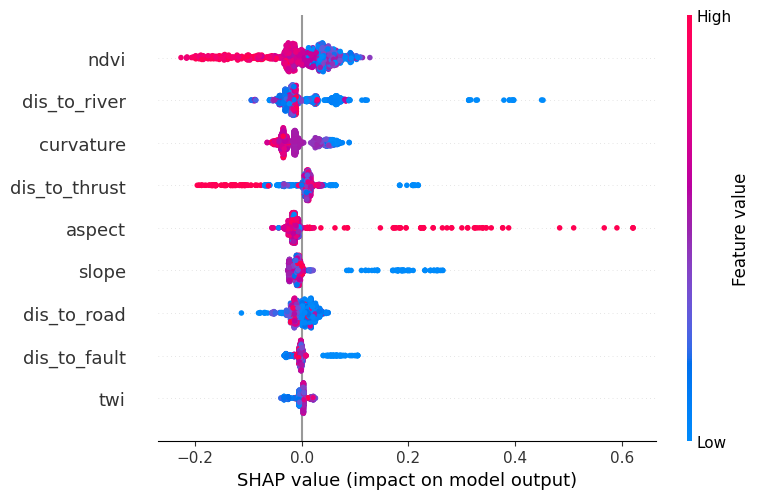

Soft Voting AUC: 0.7359749999999999
Weighted Soft Voting AUC: 0.7380374999999999


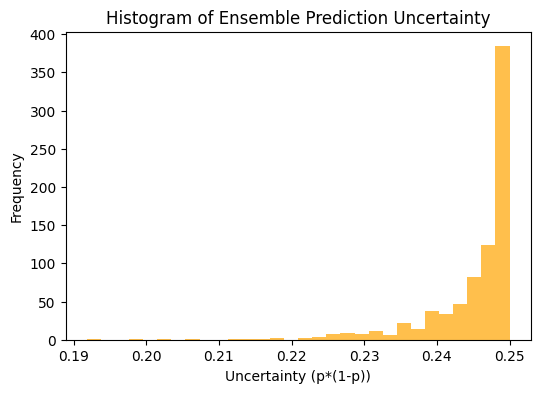

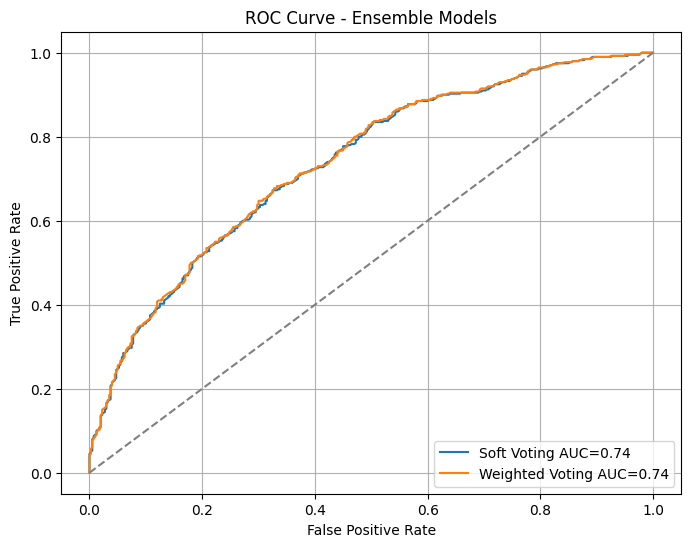

In [ ]:
# ==========================================
# 10. FEATURE IMPORTANCE (RF & XGB)
# ==========================================


rf_calibrated = trained_models["RF"]
xgb_calibrated = trained_models["XGB"]

rf_model = rf_calibrated.calibrated_classifiers_[0].estimator
xgb_model = xgb_calibrated.calibrated_classifiers_[0].estimator

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "RF_Importance": rf_model.feature_importances_,
    "XGB_Importance": xgb_model.feature_importances_
})

importance_df.sort_values("RF_Importance", ascending=False)\
    .to_excel(f"{output_path}/feature_importance.xlsx", index=False)

print("Feature importance saved successfully.")


# ==========================================
# 11. SHAP (XGBOOST)
# ==========================================
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_train)

shap.summary_plot(shap_values, X_train, show=False)
plt.tight_layout()
plt.savefig(f"{output_path}/shap_summary.png")
plt.show()


# -------------------------------
# 1️⃣ SIMPLE SOFT VOTING (Equal weight)
# -------------------------------
probs_list = [model.predict_proba(X_test)[:,1] for model in trained_models.values()]
probs_array = np.column_stack(probs_list)
soft_prob = probs_array.mean(axis=1)  # simple average

# ROC-AUC
fpr, tpr, _ = roc_curve(y_test, soft_prob)
soft_auc = auc(fpr, tpr)
print("Soft Voting AUC:", soft_auc)

# -------------------------------
# 2️⃣ WEIGHTED SOFT VOTING
# -------------------------------
model_scores = {
    "RF": results["RF"]["AUC"],
    "SVM": results["SVM"]["AUC"],
    "XGB": results["XGB"]["AUC"]
}
# model_scores = {'RF': 0.88, 'SVM': 0.82, 'XGB': 0.90}  # example: use AUC or accuracy
weights = np.array(list(model_scores.values()))
weights = weights / weights.sum()  # normalize

ensemble_prob = np.average(probs_array, axis=1, weights=weights)
ensemble_pred = (ensemble_prob >= 0.5).astype(int)

# ROC-AUC
fpr_w, tpr_w, _ = roc_curve(y_test, ensemble_prob)
weighted_auc = auc(fpr_w, tpr_w)
print("Weighted Soft Voting AUC:", weighted_auc)

# -------------------------------
# 3️⃣ UNCERTAINTY MAP
# -------------------------------
# Uncertainty per sample = p*(1-p), max at p=0.5
uncertainty = ensemble_prob * (1 - ensemble_prob)

plt.figure(figsize=(6,4))
plt.hist(uncertainty, bins=30, color='orange', alpha=0.7)
plt.title("Histogram of Ensemble Prediction Uncertainty")
plt.xlabel("Uncertainty (p*(1-p))")
plt.ylabel("Frequency")
plt.show()

# -------------------------------
# 5️⃣ ROC CURVE PLOT
# -------------------------------
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'Soft Voting AUC={soft_auc:.2f}')
plt.plot(fpr_w, tpr_w, label=f'Weighted Voting AUC={weighted_auc:.2f}')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Ensemble Models")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# 13. RASTER PREDICTION FUNCTION
# ==========================================
def predict_raster(model, raster_paths, ref_profile):

    features = []
    for path in raster_paths:
        with rasterio.open(path) as src:
            band = src.read(1).astype(np.float32)
            band[band == src.nodata] = np.nan
            features.append(band)

    stack = np.stack(features, axis=-1)
    mask = ~np.isnan(stack).any(axis=-1)

    prediction = np.full(mask.shape, np.nan, dtype=np.float32)
    prediction[mask] = model.predict_proba(stack[mask])[:,1]

    return prediction


# ==========================================
# 14. DEFINE RASTER SETS
# ==========================================
raster_files = [[
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/aspect_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/curvature_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/dis_to_fault_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/dis_to_river_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/dis_to_thrust_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/dis_to_road_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/ndvi_25x25.tif",
    # "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/ndwi_25x25.tif",
    # "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/roughness_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/twi_coarse_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/slope_25x25.tif"
    ],
    [
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/aspect_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/curvature_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/dis_to_fault_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/dis_to_river_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/dis_to_thrust_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/dis_to_road_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/ndvi_15x15.tif",
    # "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/ndwi_15x15.tif",
    # "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/roughness_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/twi_intermediate_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/slope_15x15.tif"
    ],
    [
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/aspect_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/curvature_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/dis_to_fault_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/dis_to_river_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/dis_to_thrust_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/dis_to_road_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/ndvi_3x3.tif",
    # "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/ndwi_3x3.tif",
    # "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/roughness_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/twi_finescale.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/slope_3x3.tif"
    ]]
raster_sets = {
    "25x25": raster_files[0],
    "15x15": raster_files[1],
    # "3x3": raster_files[2],
}

# Load reference profile
with rasterio.open(raster_sets["25x25"][0]) as src:
    ref_profile = src.profile

RasterioIOError: /content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/aspect_25x25.tif: No such file or directory

In [ ]:
# ==========================================
# 15. FINAL RASTER PREDICTION
# ==========================================
paths_ = []
path_ = []
for scale, rasters in raster_sets.items():

    print(f"\n🧠 Predicting {scale} rasters...")

    for name, model in trained_models.items():

        susceptibility = predict_raster(
            model,
            rasters,
            ref_profile
        )

        profile = ref_profile.copy()
        profile.update(dtype='float32', count=1, compress='lzw', nodata=np.nan)

        save_path = f"{output_path}/LS_{name}_{scale}.tif"
        path_.append(save_path)
        with rasterio.open(save_path, 'w', **profile) as dst:
            dst.write(susceptibility, 1)

        print(f"Saved: {save_path}")

        del susceptibility
        gc.collect()
    paths_.append(path_)
    path_ = []
print("\n✅ ALL MODELS TRAINED & RASTERS GENERATED SUCCESSFULLY")

In [ ]:
print(model_scores)

In [ ]:
# Optional: model weights (for weighted ensemble)
# model_scores = {"RF": 0.88, "SVM": 0.82, "XGB": 0.90}
weights = np.array(list(model_scores.values()))
weights = weights / weights.sum()  # normalize
print(weights)
# Create grid -> raster paths mapping
paths_dict = {"25x25": paths_[0], "15x15": paths_[1]}  # add "3x3" if needed

for grid, path_list in paths_dict.items():
    print(f"\nProcessing ensemble & uncertainty for grid: {grid}")

    # Read model rasters
    rasters = []
    profile = None
    for p in path_list:
        with rasterio.open(p) as src:
            data = src.read(1)
            rasters.append(data)
            if profile is None:
                profile = src.profile

    rasters = np.array(rasters)  # shape: (num_models, rows, cols)

    # Simple Soft Voting
    ensemble_prob = np.nanmean(rasters, axis=0)
    ensemble_unc = ensemble_prob * (1 - ensemble_prob)

    # Weighted Soft Voting
    ensemble_prob_weighted = np.average(rasters, axis=0, weights=weights)
    ensemble_unc_weighted = ensemble_prob_weighted * (1 - ensemble_prob_weighted)

    # Save ensemble probability map
    profile.update(dtype=rasterio.float32, count=1, compress='lzw', nodata=np.nan)
    save_prob = os.path.join(output_path, f"LS_Ensemble_{grid}_prob.tif")
    with rasterio.open(save_prob, 'w', **profile) as dst:
        dst.write(ensemble_prob.astype(np.float32), 1)
    print(f"✅ Saved ensemble probability map: {save_prob}")

    # Save uncertainty map
    save_unc = os.path.join(output_path, f"LS_Ensemble_{grid}_uncertainty.tif")
    with rasterio.open(save_unc, 'w', **profile) as dst:
        dst.write(ensemble_unc.astype(np.float32), 1)
    print(f"✅ Saved uncertainty map: {save_unc}")

    # Weighted ensemble maps
    save_prob_w = os.path.join(output_path, f"LS_Ensemble_{grid}_prob_weighted.tif")
    with rasterio.open(save_prob_w, 'w', **profile) as dst:
        dst.write(ensemble_prob_weighted.astype(np.float32), 1)
    save_unc_w = os.path.join(output_path, f"LS_Ensemble_{grid}_uncertainty_weighted.tif")
    with rasterio.open(save_unc_w, 'w', **profile) as dst:
        dst.write(ensemble_unc_weighted.astype(np.float32), 1)
    print(f"✅ Saved weighted ensemble probability & uncertainty maps")

    del rasters, ensemble_prob, ensemble_unc, ensemble_prob_weighted, ensemble_unc_weighted
    gc.collect()

In [ ]:
import numpy as np
import rasterio
import os
import gc

weights = np.array(list(model_scores.values()))
weights = weights / weights.sum()  # normalize
print(weights)
# Create grid -> raster paths mapping
paths_dict = {"25x25": paths_[0], "15x15": paths_[1]}  # add "3x3" if needed

for grid, path_list in paths_dict.items():
    print(f"\nProcessing ensemble & uncertainty for grid: {grid}")

    rasters = []
    profile = None

    # Read each model's raster for this grid
    for p in path_list:
        with rasterio.open(p) as src:
            data = src.read(1)
            rasters.append(data)
            if profile is None:
                profile = src.profile

    rasters = np.array(rasters)  # shape: (num_models, rows, cols)

    # Weighted ensemble probability (weighted mean)
    ensemble_prob_weighted = np.average(rasters, axis=0, weights=weights)

    # Model disagreement = std across models (independent of weights)
    ensemble_disagreement = np.nanstd(rasters, axis=0)

    # Save weighted ensemble probability map
    profile.update(dtype=rasterio.float32, count=1, compress='lzw', nodata=np.nan)
    save_prob = os.path.join(output_path, f"LS_Ensemble_{grid}_prob_weighted.tif")
    with rasterio.open(save_prob, 'w', **profile) as dst:
        dst.write(ensemble_prob_weighted.astype(np.float32), 1)
    print(f"✅ Saved weighted ensemble probability map: {save_prob}")

    # Save disagreement (uncertainty) map
    save_std = os.path.join(output_path, f"LS_Ensemble_{grid}_disagreement.tif")
    with rasterio.open(save_std, 'w', **profile) as dst:
        dst.write(ensemble_disagreement.astype(np.float32), 1)
    print(f"✅ Saved model disagreement map: {save_std}")

    del rasters, ensemble_prob_weighted, ensemble_disagreement
    gc.collect()